# Experiment No. 3 (Computer Laboratory – I BE AI&DS)

**Aim:**  
Implementation of Support Vector Machines (SVM) for classifying images of handwritten digits into their respective numerical classes (0 to 9).

**Dataset:**  
`load_digits(n_class=10)` from `sklearn.datasets` (Optical Recognition of Handwritten Digits, 1797 samples of 8x8 greyscale images).

**Objectives:**  
1. Load and explore the handwritten digits dataset (64 features per sample, 10 digit classes).
2. Visualize sample handwritten digit images in an 8x8 grid and individual view function.
3. Apply non-linear dimensionality reduction (Isomap Manifold Learning) to project 64 dimensions into 2D.
4. Train a Support Vector Classifier (`SVC` with RBF kernel, `gamma=0.001`, `C=100`) on training samples.
5. Evaluate classification performance using Confusion Matrix heatmap and Classification Report.

In [1]:
# Cell 1 - Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.manifold import Isomap
from sklearn import svm
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
# Cell 2 - Load and Inspect Handwritten Digits Dataset
digits = load_digits(n_class=10)

main_data = digits['data']
targets = digits['target']

print("Dataset Shape:", main_data.shape)
print("Number of Classes (0-9):", len(digits.target_names))
print("\nFlattened array of first digit (64 pixels):")
print(main_data[0])

print("\nReshaped 8x8 matrix representation of first digit:")
print(main_data[0].reshape(8, 8))

print("\nFirst 9 targets:", targets[0:9])

Dataset Shape: (1797, 64)
Number of Classes (0-9): 10

Flattened array of first digit (64 pixels):
[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]

Reshaped 8x8 matrix representation of first digit:
[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]

First 9 targets: [0 1 2 3 4 5 6 7 8]


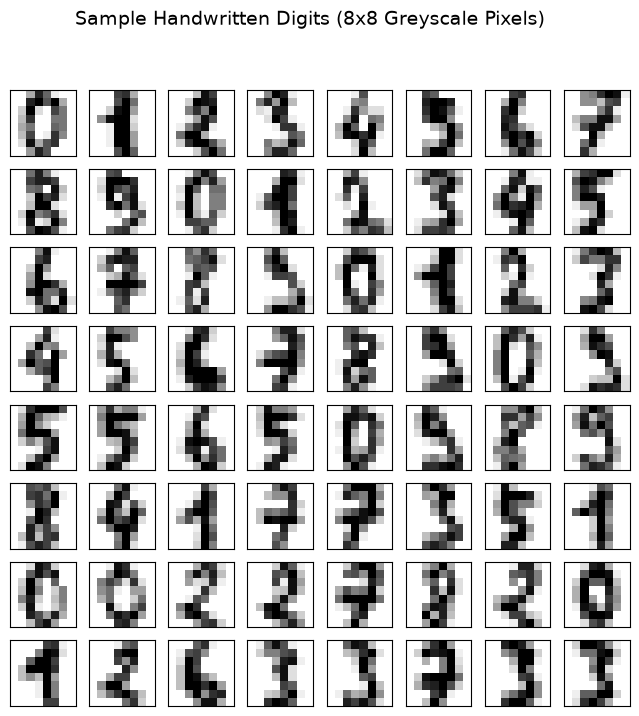

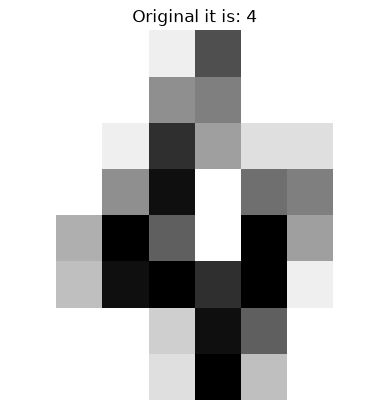

In [3]:
# Cell 3 - Visualize Handwritten Digit Images
# Plot an 8x8 grid of sample digit images
fig, ax = plt.subplots(8, 8, figsize=(8, 8))
for i, axi in enumerate(ax.flat):
    axi.imshow(digits.images[i], cmap='binary')
    axi.set(xticks=[], yticks=[])
plt.suptitle("Sample Handwritten Digits (8x8 Greyscale Pixels)", fontsize=14)
plt.show()

# Function to view a single digit image with true target label
def view_digit(index):
    plt.imshow(digits.images[index], cmap=plt.cm.gray_r)
    plt.title('Original it is: ' + str(digits.target[index]))
    plt.axis('off')
    plt.show()

# View sample digit at index 4
view_digit(4)

c:\Users\bsais\miniconda3\Lib\site-packages\sklearn\manifold\_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
c:\Users\bsais\miniconda3\Lib\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


Sample 70 Projected Coordinates: -56.87848641513015 62.09402672588068


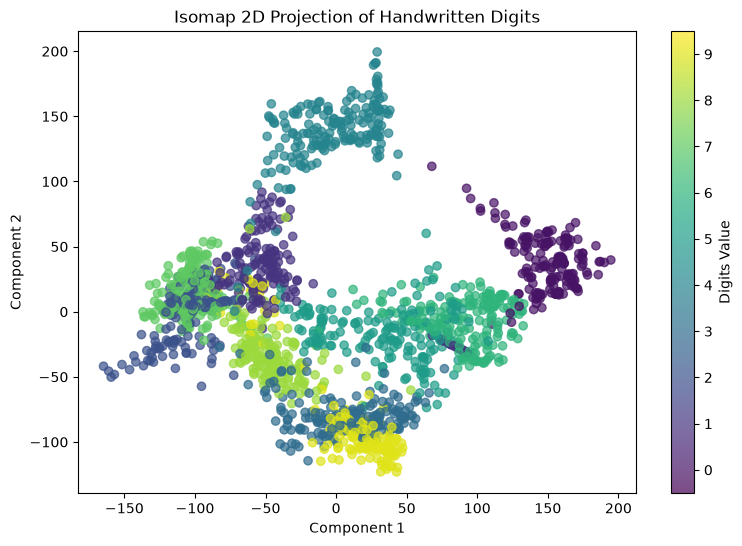

In [4]:
# Cell 4 - Manifold Learning (Isomap 2D Projection)
iso = Isomap(n_components=2)
projection = iso.fit_transform(digits.data) # Project 64 dimensions to 2 dimensions

print("Sample 70 Projected Coordinates:", projection[:, 0][70], projection[:, 1][70])

# Scatter plot colored by digit class
plt.figure(figsize=(9, 6))
plt.scatter(projection[:, 0], projection[:, 1], c=digits.target, cmap="viridis", alpha=0.7)
plt.colorbar(ticks=range(10), label='Digits Value')
plt.clim(-0.5, 9.5)
plt.title("Isomap 2D Projection of Handwritten Digits")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

In [5]:
# Cell 5 - Train Support Vector Classifier (SVC) and Predict
# gamma: controls kernel width for non-linear hyperplane
# C: error penalty parameter trading off margin width vs training accuracy
svc = svm.SVC(gamma=0.001, C=100)

# Split: Train on first 1500 samples, test on remaining samples
svc.fit(main_data[:1500], targets[:1500])
predictions = svc.predict(main_data[1501:])

# Display sample (prediction, actual) pairs
print("First 30 (Predicted, Actual) pairs:")
print(list(zip(predictions, targets[1501:]))[:30])

First 30 (Predicted, Actual) pairs:
[(np.int64(7), np.int64(7)), (np.int64(4), np.int64(4)), (np.int64(6), np.int64(6)), (np.int64(3), np.int64(3)), (np.int64(1), np.int64(1)), (np.int64(3), np.int64(3)), (np.int64(9), np.int64(9)), (np.int64(1), np.int64(1)), (np.int64(7), np.int64(7)), (np.int64(6), np.int64(6)), (np.int64(8), np.int64(8)), (np.int64(4), np.int64(4)), (np.int64(3), np.int64(3)), (np.int64(1), np.int64(1)), (np.int64(4), np.int64(4)), (np.int64(0), np.int64(0)), (np.int64(5), np.int64(5)), (np.int64(3), np.int64(3)), (np.int64(6), np.int64(6)), (np.int64(9), np.int64(9)), (np.int64(6), np.int64(6)), (np.int64(1), np.int64(1)), (np.int64(7), np.int64(7)), (np.int64(5), np.int64(5)), (np.int64(4), np.int64(4)), (np.int64(4), np.int64(4)), (np.int64(7), np.int64(7)), (np.int64(2), np.int64(2)), (np.int64(8), np.int64(8)), (np.int64(2), np.int64(2))]


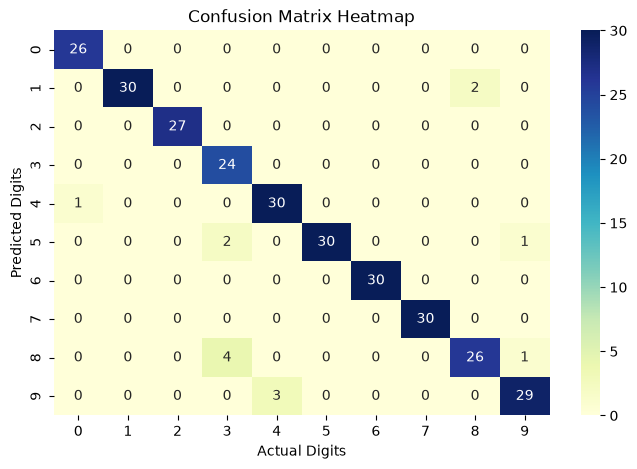

Confusion Matrix Array:
[[26  0  0  0  0  0  0  0  0  0]
 [ 0 30  0  0  0  0  0  0  2  0]
 [ 0  0 27  0  0  0  0  0  0  0]
 [ 0  0  0 24  0  0  0  0  0  0]
 [ 1  0  0  0 30  0  0  0  0  0]
 [ 0  0  0  2  0 30  0  0  0  1]
 [ 0  0  0  0  0  0 30  0  0  0]
 [ 0  0  0  0  0  0  0 30  0  0]
 [ 0  0  0  4  0  0  0  0 26  1]
 [ 0  0  0  0  3  0  0  0  0 29]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        26
           1       1.00      0.94      0.97        32
           2       1.00      1.00      1.00        27
           3       0.80      1.00      0.89        24
           4       0.91      0.97      0.94        31
           5       1.00      0.91      0.95        33
           6       1.00      1.00      1.00        30
           7       1.00      1.00      1.00        30
           8       0.93      0.84      0.88        31
           9       0.94      0.91      0.92        32

    accuracy             

In [6]:
# Cell 6 - Confusion Matrix and Classification Report
cm = confusion_matrix(predictions, targets[1501:])
conf_matrix = pd.DataFrame(data=cm)

# Plot Confusion Matrix Heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap="YlGnBu")
plt.xlabel("Actual Digits")
plt.ylabel("Predicted Digits")
plt.title("Confusion Matrix Heatmap")
plt.show()

print("Confusion Matrix Array:")
print(cm)

print("\nClassification Report:")
print(classification_report(predictions, targets[1501:]))